# Control Geometry of Static Degree- and Topology-Informed Driver Sets

This notebook collects the results for the control-geometry section. It is meant to make it easy to:

- compare static degree- and cycle-based driver sets on scalar energy and geometric summaries,
- quantify how strongly topology broadens or rebalances the controllable subspace,
- visualize the relationship between scalar energy and geometry across scales,
- summarize how much the hardest controllability directions overlap between methods.

The main comparison here is between `degree_strength` and `cycle_participation` under the **static** construction, since that is the cleanest version of the manuscript story.

Set `HOC_RUN` (default `main`) to choose the run directory under `runs/`; `HOC_RUN=results` reads the legacy pre-cleanup tree.

In [1]:
from pathlib import Path
import os
import sys
os.environ.setdefault('MPLCONFIGDIR', '/private/tmp/matplotlib')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

REPO_ROOT = Path.cwd().resolve().parents[0] if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
SRC_ROOT = REPO_ROOT / 'src'
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

from hoc.runs import resolve_run_dir, figures_dir

RUN = os.environ.get('HOC_RUN', 'main')  # 'results' = legacy pre-cleanup tree
RESULTS = resolve_run_dir(RUN)
FIGURES_DIR = figures_dir(RESULTS, 'section_control_geometry')

sns.set_theme(context='talk', style='whitegrid')
palette = {
    'degree_strength': '#cc7a29',
    'cycle_participation': '#4c72b0',
}
label_map = {
    'degree_strength': 'Degree',
    'cycle_participation': 'Topology',
}
scale_palette = {68: '#6a51a3', 114: '#3182bd', 219: '#31a354'}


In [2]:
geometry = pd.read_csv(RESULTS / 'primary' / 'geometry_metrics.csv')
overlap = pd.read_csv(RESULTS / 'primary' / 'eigenspace_overlap.csv')
methods = ['degree_strength', 'cycle_participation']
geometry = geometry[(geometry['method'].isin(methods)) & (geometry['selection_strategy'] == 'static')].copy()
geometry.head()


,subject_id,scale,k,method,selection_strategy,log10_average_energy,effective_rank,participation_ratio,log10_condition_number,log_min_eigenvalue
0,sub-000,68,1,degree_strength,static,6.800841,1.675523,1.397570,4.946461,-11.512925
2,sub-000,68,1,cycle_participation,static,6.801388,1.819955,1.512962,4.511342,-11.512925
112,sub-000,68,2,degree_strength,static,6.776458,2.483251,1.919455,5.081490,-11.512925
114,sub-000,68,2,cycle_participation,static,6.775227,2.684085,2.137513,4.941877,-11.512925
224,sub-000,68,3,degree_strength,static,6.758232,2.585864,1.864077,5.287005,-11.512925


## Subject-level and subject-averaged summaries


In [3]:
summary_by_scale_method = (
    geometry.groupby(['scale', 'method'], as_index=False)
    .agg(
        n_rows=('subject_id', 'size'),
        n_subjects=('subject_id', 'nunique'),
        mean_log10_average_energy=('log10_average_energy', 'mean'),
        sem_log10_average_energy=('log10_average_energy', lambda x: x.std(ddof=1) / np.sqrt(len(x))),
        mean_effective_rank=('effective_rank', 'mean'),
        sem_effective_rank=('effective_rank', lambda x: x.std(ddof=1) / np.sqrt(len(x))),
        mean_participation_ratio=('participation_ratio', 'mean'),
        sem_participation_ratio=('participation_ratio', lambda x: x.std(ddof=1) / np.sqrt(len(x))),
        mean_log10_condition_number=('log10_condition_number', 'mean'),
        sem_log10_condition_number=('log10_condition_number', lambda x: x.std(ddof=1) / np.sqrt(len(x))),
        mean_log_min_eigenvalue=('log_min_eigenvalue', 'mean'),
    )
)
summary_by_scale_method


,scale,method,n_rows,n_subjects,mean_log10_average_energy,sem_log10_average_energy,mean_effective_rank,sem_effective_rank,mean_participation_ratio,sem_participation_ratio,mean_log10_condition_number,sem_log10_condition_number,mean_log_min_eigenvalue
0,68,cycle_participation,280,70,6.767585,0.001838,3.117983,0.084872,2.601820,0.074124,4.839342,0.017061,-11.512925
1,68,degree_strength,280,70,6.768161,0.001774,2.282182,0.044271,1.697996,0.025782,5.336827,0.011295,-11.512925
2,114,cycle_participation,280,70,7.019389,0.001067,3.250316,0.093741,2.783395,0.083330,4.689747,0.016078,-11.512925
3,114,degree_strength,280,70,7.018419,0.001044,2.271570,0.041713,1.670794,0.023216,5.283402,0.011798,-11.512925
4,219,cycle_participation,280,70,7.320842,0.000562,3.454992,0.102500,3.005105,0.091858,4.541525,0.009544,-11.512925
5,219,degree_strength,280,70,7.319745,0.000565,2.658076,0.059068,1.938130,0.037337,5.178608,0.012729,-11.512925


In [4]:
subject_avg = (
    geometry.groupby(['subject_id', 'scale', 'method'], as_index=False)
    .agg(
        log10_average_energy=('log10_average_energy', 'mean'),
        effective_rank=('effective_rank', 'mean'),
        participation_ratio=('participation_ratio', 'mean'),
        log10_condition_number=('log10_condition_number', 'mean'),
        log_min_eigenvalue=('log_min_eigenvalue', 'mean'),
    )
)
subject_avg.head()


,subject_id,scale,method,log10_average_energy,effective_rank,participation_ratio,log10_condition_number,log_min_eigenvalue
0,sub-000,68,cycle_participation,6.759813,3.188155,2.416116,4.910770,-11.512925
1,sub-000,68,degree_strength,6.761756,2.642543,1.928270,5.169934,-11.512925
2,sub-000,114,cycle_participation,7.016582,3.533728,3.170516,4.541873,-11.512925
3,sub-000,114,degree_strength,7.015136,2.852349,2.096932,5.146301,-11.512925
4,sub-000,219,cycle_participation,7.317744,3.800642,3.240975,4.503087,-11.512925


In [5]:
cycle_vs_degree = []
for metric in ['log10_average_energy', 'effective_rank', 'participation_ratio', 'log10_condition_number', 'log_min_eigenvalue']:
    wide = subject_avg.pivot(index=['subject_id', 'scale'], columns='method', values=metric).reset_index()
    wide['cycle_minus_degree'] = wide['cycle_participation'] - wide['degree_strength']
    for scale, subset in wide.groupby('scale'):
        stat, p = wilcoxon(subset['cycle_minus_degree'])
        cycle_vs_degree.append({
            'metric': metric,
            'scale': scale,
            'cycle_minus_degree_mean': subset['cycle_minus_degree'].mean(),
            'statistic': stat,
            'p_value': p,
        })
cycle_vs_degree = pd.DataFrame(cycle_vs_degree).sort_values(['metric', 'scale']).reset_index(drop=True)
cycle_vs_degree['p_value_holm_local'] = multipletests(cycle_vs_degree['p_value'], method='holm')[1]
cycle_vs_degree['reject_holm_local'] = cycle_vs_degree['p_value_holm_local'] < 0.05
cycle_vs_degree


/opt/anaconda3/lib/python3.12/site-packages/scipy/stats/_wilcoxon.py:172: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se


,metric,scale,cycle_minus_degree_mean,statistic,p_value,p_value_holm_local,reject_holm_local
0,effective_rank,68,0.835802,0.0,3.559469e-13,5.339204e-12,True
1,effective_rank,114,0.978746,0.0,3.559469e-13,5.339204e-12,True
2,effective_rank,219,0.796916,0.0,3.559469e-13,5.339204e-12,True
3,log10_average_energy,68,-0.000576,880.0,3.388679e-02,1.355472e-01,False
4,log10_average_energy,114,0.000969,611.0,2.193221e-04,1.096610e-03,True
5,log10_average_energy,219,0.001097,82.0,1.110060e-11,6.660357e-11,True
6,log10_condition_number,68,-0.497485,0.0,3.559469e-13,5.339204e-12,True
7,log10_condition_number,114,-0.593655,0.0,3.559469e-13,5.339204e-12,True
8,log10_condition_number,219,-0.637083,0.0,3.559469e-13,5.339204e-12,True
9,log_min_eigenvalue,68,0.000000,0.0,NaN,NaN,False


## Figure: scalar energy versus geometry

This figure makes the basic tradeoff visible: topology is not consistently lower in scalar energy, but it tends to occupy a different geometric regime with higher effective rank and participation ratio.


PosixPath('/Users/cartersale/Research/projects/higher_order_connectomes/figures/section_control_geometry/geometry_energy_scatter.svg')

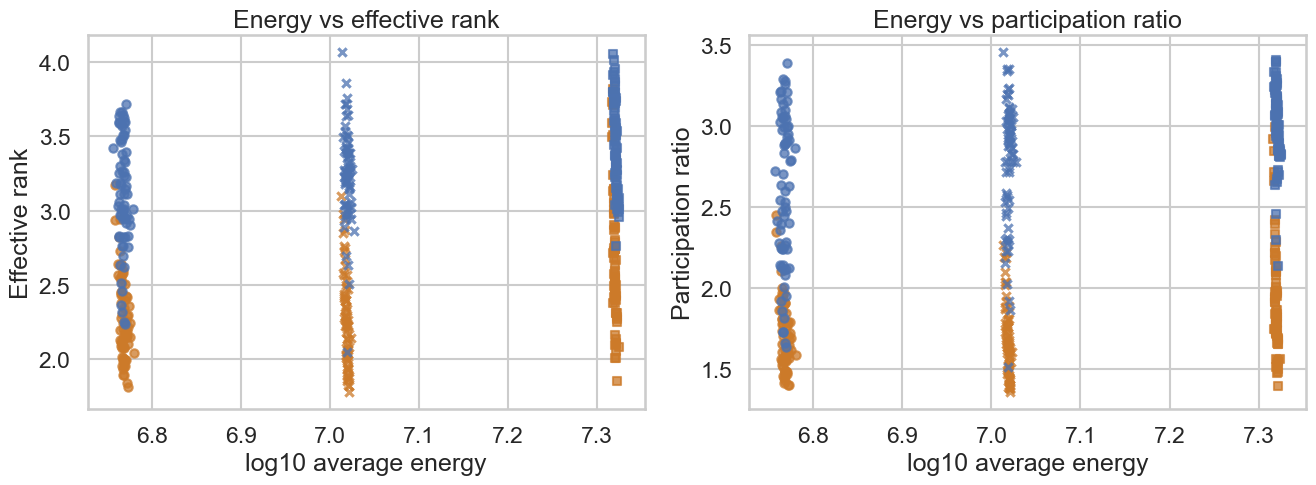

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))
for scale in sorted(subject_avg['scale'].unique()):
    subset = subject_avg[subject_avg['scale'] == scale]
    for method in methods:
        sub = subset[subset['method'] == method]
        axes[0].scatter(
            sub['log10_average_energy'],
            sub['effective_rank'],
            s=36,
            alpha=0.75,
            color=palette[method],
            marker='o' if scale == 68 else ('x' if scale == 114 else 's'),
            label=f"{label_map[method]} | {scale}" if method == 'degree_strength' else None,
        )
        axes[1].scatter(
            sub['log10_average_energy'],
            sub['participation_ratio'],
            s=36,
            alpha=0.75,
            color=palette[method],
            marker='o' if scale == 68 else ('x' if scale == 114 else 's'),
            label=f"{label_map[method]} | {scale}" if method == 'degree_strength' else None,
        )
axes[0].set_xlabel('log10 average energy')
axes[0].set_ylabel('Effective rank')
axes[0].set_title('Energy vs effective rank')
axes[1].set_xlabel('log10 average energy')
axes[1].set_ylabel('Participation ratio')
axes[1].set_title('Energy vs participation ratio')
fig.tight_layout()
out = FIGURES_DIR / 'geometry_energy_scatter.svg'
fig.savefig(out, bbox_inches='tight')
out


## Figure: cycle-minus-degree geometry differences by scale

These are the clean comparison panels for the paper: positive values favor topology for rank-like metrics, while negative values favor topology for condition number because lower condition number is better.


PosixPath('/Users/cartersale/Research/projects/higher_order_connectomes/figures/section_control_geometry/geometry_cycle_minus_degree_by_scale.svg')

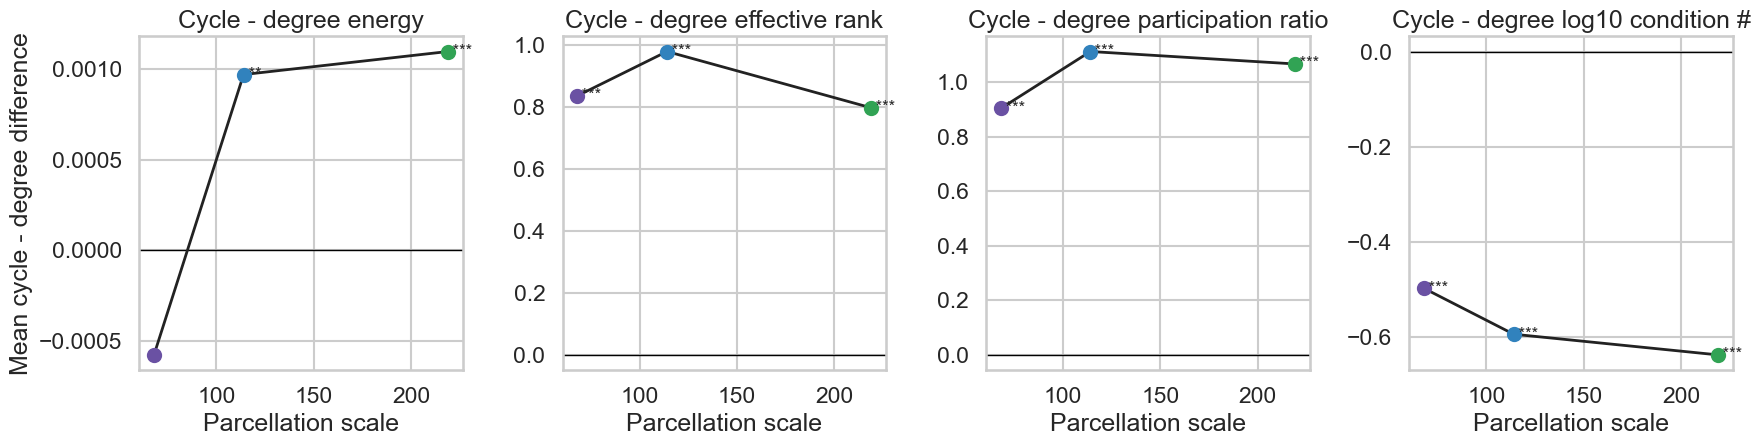

In [7]:
delta_summary = cycle_vs_degree[cycle_vs_degree['metric'].isin(['log10_average_energy', 'effective_rank', 'participation_ratio', 'log10_condition_number'])].copy()
metric_order = ['log10_average_energy', 'effective_rank', 'participation_ratio', 'log10_condition_number']
title_map = {
    'log10_average_energy': 'Cycle - degree energy',
    'effective_rank': 'Cycle - degree effective rank',
    'participation_ratio': 'Cycle - degree participation ratio',
    'log10_condition_number': 'Cycle - degree log10 condition #',
}
fig, axes = plt.subplots(1, 4, figsize=(18, 4.8), sharex=True)
for ax, metric in zip(axes, metric_order):
    subset = delta_summary[delta_summary['metric'] == metric].sort_values('scale')
    ax.axhline(0, color='black', linewidth=1)
    ax.plot(subset['scale'], subset['cycle_minus_degree_mean'], color='#222222', linewidth=2)
    for row in subset.itertuples(index=False):
        ax.scatter(row.scale, row.cycle_minus_degree_mean, s=90, color=scale_palette[row.scale], zorder=3)
        star = '***' if row.p_value_holm_local < 0.001 else ('**' if row.p_value_holm_local < 0.01 else ('*' if row.p_value_holm_local < 0.05 else ''))
        if star:
            ax.text(row.scale, row.cycle_minus_degree_mean, f' {star}', va='center', fontsize=12)
    ax.set_title(title_map[metric])
    ax.set_xlabel('Parcellation scale')
axes[0].set_ylabel('Mean cycle - degree difference')
fig.tight_layout()
out = FIGURES_DIR / 'geometry_cycle_minus_degree_by_scale.svg'
fig.savefig(out, bbox_inches='tight')
out


## Figure: condition number paired summaries

A simpler view of the anisotropy result.


PosixPath('/Users/cartersale/Research/projects/higher_order_connectomes/figures/section_control_geometry/geometry_condition_number_by_scale.svg')

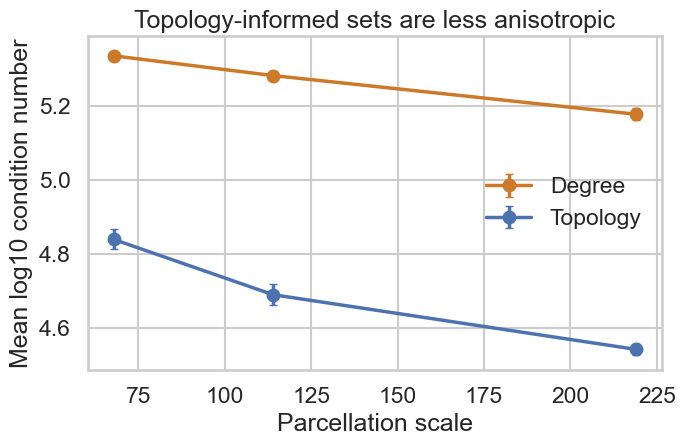

In [8]:
condition_summary = (
    subject_avg.groupby(['scale', 'method'], as_index=False)
    .agg(
        mean_log10_condition_number=('log10_condition_number', 'mean'),
        sem_log10_condition_number=('log10_condition_number', lambda x: x.std(ddof=1) / np.sqrt(len(x))),
    )
)
fig, ax = plt.subplots(figsize=(7.2, 4.8))
for method in methods:
    subset = condition_summary[condition_summary['method'] == method].sort_values('scale')
    ax.errorbar(
        subset['scale'],
        subset['mean_log10_condition_number'],
        yerr=subset['sem_log10_condition_number'],
        marker='o',
        linewidth=2.5,
        capsize=3,
        color=palette[method],
        label=label_map[method],
    )
ax.set_xlabel('Parcellation scale')
ax.set_ylabel('Mean log10 condition number')
ax.set_title('Topology-informed sets are less anisotropic')
ax.legend(frameon=False, title='')
fig.tight_layout()
out = FIGURES_DIR / 'geometry_condition_number_by_scale.svg'
fig.savefig(out, bbox_inches='tight')
out


## Hard-direction overlap

Instead of a heatmap, this notebook uses a simple line view of the two main static comparisons:

- degree static vs topology static,
- degree greedy vs topology greedy,

plus the within-method static-vs-greedy overlaps for context.


In [9]:
pairs = [
    ('degree_strength', 'static', 'cycle_participation', 'static', 'Degree static vs topology static'),
    ('degree_strength', 'greedy', 'cycle_participation', 'greedy', 'Degree greedy vs topology greedy'),
    ('degree_strength', 'static', 'degree_strength', 'greedy', 'Degree static vs degree greedy'),
    ('cycle_participation', 'static', 'cycle_participation', 'greedy', 'Topology static vs topology greedy'),
]
rows = []
for method_a, strategy_a, method_b, strategy_b, label in pairs:
    subset = overlap[
        (overlap['method_a'] == method_a)
        & (overlap['strategy_a'] == strategy_a)
        & (overlap['method_b'] == method_b)
        & (overlap['strategy_b'] == strategy_b)
    ].copy()
    subset['pair_label'] = label
    rows.append(subset)
overlap_focus = pd.concat(rows, ignore_index=True)
overlap_summary = (
    overlap_focus.groupby(['pair_label', 'scale'], as_index=False)
    .agg(
        mean_overlap=('overlap', 'mean'),
        sem_overlap=('overlap', lambda x: x.std(ddof=1) / np.sqrt(len(x))),
    )
)
overlap_summary


,pair_label,scale,mean_overlap,sem_overlap
0,Degree greedy vs topology greedy,68,0.448920,0.007208
1,Degree greedy vs topology greedy,114,0.433764,0.007728
2,Degree greedy vs topology greedy,219,0.411081,0.006643
3,Degree static vs degree greedy,68,0.595706,0.014676
4,Degree static vs degree greedy,114,0.588902,0.014850
5,Degree static vs degree greedy,219,0.584891,0.015335
6,Degree static vs topology static,68,0.439860,0.006893
7,Degree static vs topology static,114,0.431372,0.007468
8,Degree static vs topology static,219,0.408564,0.006271
9,Topology static vs topology greedy,68,0.593147,0.015075


PosixPath('/Users/cartersale/Research/projects/higher_order_connectomes/figures/section_control_geometry/geometry_eigenspace_overlap_lines.svg')

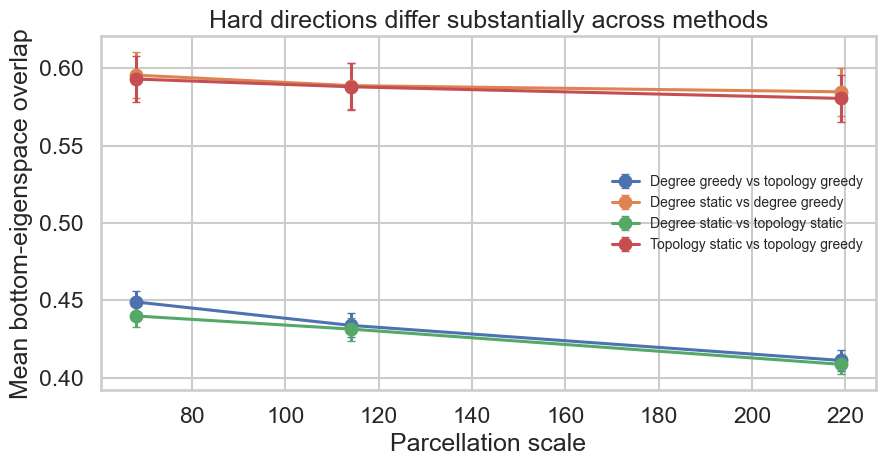

In [10]:
fig, ax = plt.subplots(figsize=(9.2, 5.0))
for pair_label, subset in overlap_summary.groupby('pair_label'):
    subset = subset.sort_values('scale')
    ax.errorbar(
        subset['scale'],
        subset['mean_overlap'],
        yerr=subset['sem_overlap'],
        marker='o',
        linewidth=2.2,
        capsize=3,
        label=pair_label,
    )
ax.set_xlabel('Parcellation scale')
ax.set_ylabel('Mean bottom-eigenspace overlap')
ax.set_title('Hard directions differ substantially across methods')
ax.legend(frameon=False, fontsize=10, title='')
fig.tight_layout()
out = FIGURES_DIR / 'geometry_eigenspace_overlap_lines.svg'
fig.savefig(out, bbox_inches='tight')
out


## Reachable-state cloud companion

The paper-scale animation assets live elsewhere, but we note them here so the geometry notebook remains the natural place to look for them.


In [11]:
cloud_asset_dir = figures_dir(RESULTS, 'animation_assets')
cloud_assets = sorted(cloud_asset_dir.glob('reachable_state_cloud_*'))
[p.name for p in cloud_assets[:10]]


['reachable_state_cloud_scale-114_k-5_static_sub-014.json',
 'reachable_state_cloud_scale-114_k-5_static_sub-014.npz',
 'reachable_state_cloud_scale-114_k-5_static_sub-014_preview.svg']

## Notes for interpretation


In [14]:
print('Cycle minus degree summary (subject-averaged over k)')
print(cycle_vs_degree[['metric', 'scale', 'cycle_minus_degree_mean', 'p_value_holm_local', 'reject_holm_local']].to_string(index=False))

print('Static overlap summary') 
print(overlap_summary.to_string(index=False))

print('Important note: log_min_eigenvalue is pinned by the fixed epsilon floor in the current setup, so it should not be treated as an interpretable biological result.')


Cycle minus degree summary (subject-averaged over k)
                metric  scale  cycle_minus_degree_mean  p_value_holm_local  reject_holm_local
        effective_rank     68                 0.835802        5.339204e-12               True
        effective_rank    114                 0.978746        5.339204e-12               True
        effective_rank    219                 0.796916        5.339204e-12               True
  log10_average_energy     68                -0.000576        1.355472e-01              False
  log10_average_energy    114                 0.000969        1.096610e-03               True
  log10_average_energy    219                 0.001097        6.660357e-11               True
log10_condition_number     68                -0.497485        5.339204e-12               True
log10_condition_number    114                -0.593655        5.339204e-12               True
log10_condition_number    219                -0.637083        5.339204e-12               True
    log